# Análise de Churn — Telco Customer Churn

Análise da base de clientes de uma operadora de telecom (7.043 clientes, 21 colunas) para entender quem cancela o serviço (`Churn = Yes`) e quando.

1. Tabelas de distribuição de frequência (contínuas e categóricas)
2. Medidas de posição e dispersão
3. Taxa de churn por variável, com intervalo de confiança
4. Análise de sobrevivência (Kaplan-Meier)
5. Testes de associação com o churn
6. Modelos de previsão: variáveis derivadas, comparação, calibração, limiar por custo e explicação por cliente

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.append(os.path.abspath('../src'))
from estatistica import (calcular_classes, classificar, criar_tabela_frequencia,
                         formatar_tabela, kaplan_meier, mediana_sobrevivencia, medidas_resumo,
                         moda_czuber, resumo_categoricas, taxa_churn, teste_log_rank,
                         teste_mann_whitney, teste_qui_quadrado)
from modelagem import contribuicoes, criar_features, principais_motivos

df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
# TotalCharges vem como texto: 11 clientes com tenure 0 têm o campo vazio
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# SeniorCitizen é binária (0/1), não contínua
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# tenure é discreta (meses): faixas de 6 meses no lugar de Sturges
LARGURA = {'tenure': 6}
taxa_geral = (df['Churn'] == 'Yes').mean() * 100

# Gráficos usados no README
FIGURAS = '../reports/figures'
os.makedirs(FIGURAS, exist_ok=True)

# Estilo dos gráficos: cores fixas por série, grade discreta
AZUL, LARANJA, VERDE, CINZA = '#2a78d6', '#eb6834', '#1baf7a', '#8a8a85'
TEXTO_SECUNDARIO = '#55554f'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e4e4e0',
    'grid.linewidth': 0.8,
})

## Variáveis disponíveis

In [2]:
continuas = df.select_dtypes(include='number').columns.tolist()
categoricas = [c for c in df.columns if c not in continuas and c != 'customerID']

print('VARIÁVEIS NUMÉRICAS (tabela com intervalos de classe):')
for col in continuas:
    print(f'   -> {col}')
print('\nVARIÁVEIS CATEGÓRICAS (tabela de frequência simples):')
for col in categoricas:
    print(f'   -> {col}')

VARIÁVEIS NUMÉRICAS (tabela com intervalos de classe):
   -> tenure
   -> MonthlyCharges
   -> TotalCharges

VARIÁVEIS CATEGÓRICAS (tabela de frequência simples):
   -> gender
   -> SeniorCitizen
   -> Partner
   -> Dependents
   -> PhoneService
   -> MultipleLines
   -> InternetService
   -> OnlineSecurity
   -> OnlineBackup
   -> DeviceProtection
   -> TechSupport
   -> StreamingTV
   -> StreamingMovies
   -> Contract
   -> PaperlessBilling
   -> PaymentMethod
   -> Churn


## 1. Distribuição de frequência — variáveis contínuas

`tenure` usa faixas de 6 meses, porque é contada em meses inteiros. `MonthlyCharges` e `TotalCharges` usam a regra de Sturges. O histograma é desenhado sobre as mesmas classes da tabela.

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (tenure),,,,,,
0 |--- 6,3.00,1371,0.1947,19.47%,1371,19.47%
6 |--- 12,9.00,698,0.0991,9.91%,2069,29.38%
12 |--- 18,15.00,568,0.0806,8.06%,2637,37.44%
18 |--- 24,21.00,479,0.0680,6.80%,3116,44.24%
24 |--- 30,27.00,453,0.0643,6.43%,3569,50.67%
30 |--- 36,33.00,423,0.0601,6.01%,3992,56.68%
36 |--- 42,39.00,364,0.0517,5.17%,4356,61.85%
42 |--- 48,45.00,384,0.0545,5.45%,4740,67.30%
48 |--- 54,51.00,416,0.0591,5.91%,5156,73.21%


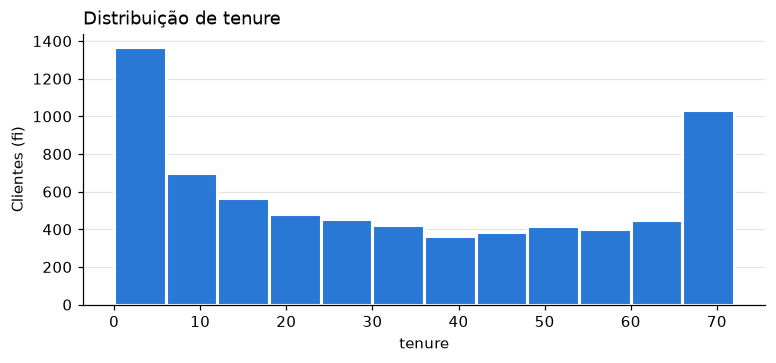

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (MonthlyCharges),,,,,,
18.25 |--- 25.43,21.84,1511,0.2145,21.45%,1511,21.45%
25.43 |--- 32.61,29.02,179,0.0254,2.54%,1690,24.00%
32.61 |--- 39.79,36.20,143,0.0203,2.03%,1833,26.03%
39.79 |--- 46.96,43.38,311,0.0442,4.42%,2144,30.44%
46.96 |--- 54.14,50.55,372,0.0528,5.28%,2516,35.72%
54.14 |--- 61.32,57.73,478,0.0679,6.79%,2994,42.51%
61.32 |--- 68.50,64.91,280,0.0398,3.98%,3274,46.49%
68.50 |--- 75.68,72.09,750,0.1065,10.65%,4024,57.13%
75.68 |--- 82.86,79.27,614,0.0872,8.72%,4638,65.85%


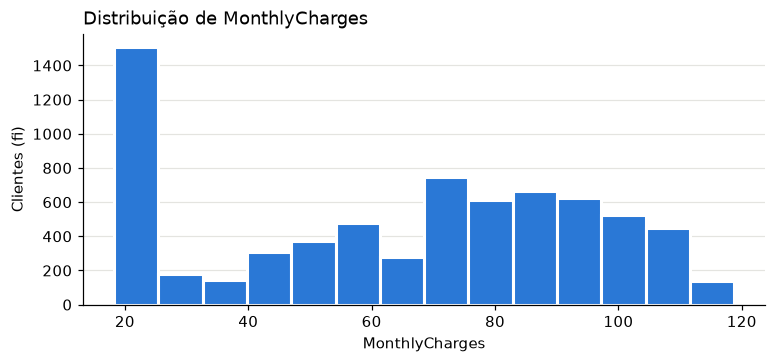

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (TotalCharges),,,,,,
18.80 |--- 637.80,328.30,2269,0.3227,32.27%,2269,32.27%
"637.80 |--- 1,256.80",947.30,1026,0.1459,14.59%,3295,46.86%
"1,256.80 |--- 1,875.80","1,566.30",783,0.1113,11.13%,4078,57.99%
"1,875.80 |--- 2,494.80","2,185.30",449,0.0639,6.39%,4527,64.38%
"2,494.80 |--- 3,113.80","2,804.30",379,0.0539,5.39%,4906,69.77%
"3,113.80 |--- 3,732.80","3,423.30",336,0.0478,4.78%,5242,74.54%
"3,732.80 |--- 4,351.80","4,042.30",328,0.0466,4.66%,5570,79.21%
"4,351.80 |--- 4,970.80","4,661.30",312,0.0444,4.44%,5882,83.65%
"4,970.80 |--- 5,589.80","5,280.30",260,0.0370,3.70%,6142,87.34%


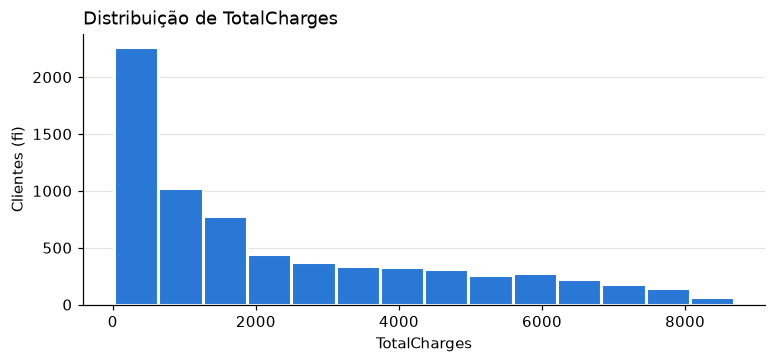

In [3]:
for coluna in continuas:
    largura = LARGURA.get(coluna)
    display(formatar_tabela(criar_tabela_frequencia(df, coluna, largura)))

    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.hist(df[coluna].dropna(), bins=calcular_classes(df[coluna], largura), color=AZUL,
            edgecolor='white', linewidth=2)
    ax.set_title(f'Distribuição de {coluna}', loc='left')
    ax.set_xlabel(coluna)
    ax.set_ylabel('Clientes (fi)')
    ax.grid(axis='x', visible=False)
    plt.show()

## 2. Distribuição de frequência — variáveis categóricas

In [4]:
display(formatar_tabela(resumo_categoricas(df, categoricas)))

## 3. Medidas de posição e dispersão

A moda das variáveis contínuas é estimada pela fórmula de Czuber sobre a classe modal da tabela de frequência, já que quase não há valores repetidos exatos.

In [5]:
resumo = pd.DataFrame({c: medidas_resumo(df[c], LARGURA.get(c)) for c in continuas})
display(resumo.style.format('{:,.2f}'))

for coluna in continuas:
    classe, _ = moda_czuber(df[coluna], LARGURA.get(coluna))
    print(f'Classe modal de {coluna}: {classe.left:,.2f} |--- {classe.right:,.2f}')

,tenure,MonthlyCharges,TotalCharges
Média,32.37,64.76,"2,283.30"
Mediana,29.00,70.35,"1,397.47"
Moda (Czuber),4.02,22.07,418.72
Desvio Padrão,24.56,30.09,"2,266.77"
Coef. Variação (%),75.87,46.46,99.28
Mínimo,0.00,18.25,18.80
Q1,9.00,35.50,401.45
Q3,55.00,89.85,"3,794.74"
Máximo,72.00,118.75,"8,684.80"
Amplitude Interquartil,46.00,54.35,"3,393.29"


Classe modal de tenure: 0.00 |--- 6.00
Classe modal de MonthlyCharges: 18.25 |--- 25.43
Classe modal de TotalCharges: 18.80 |--- 637.80


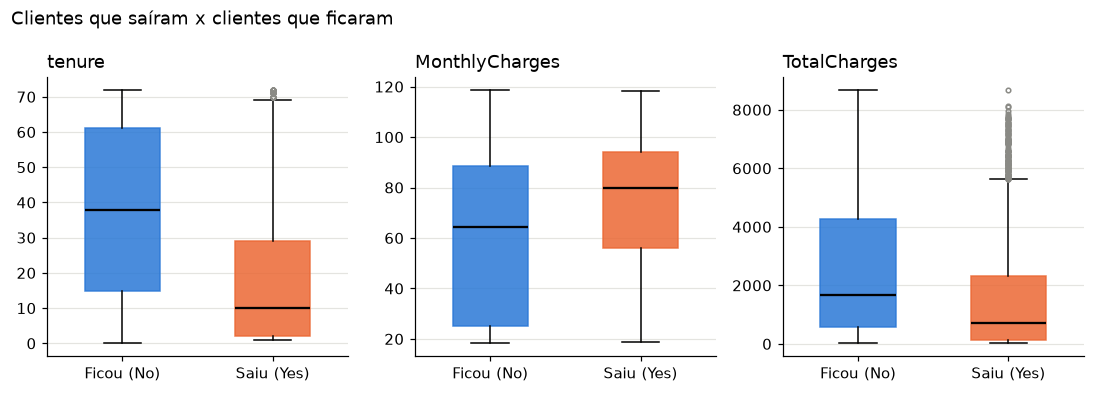

In [6]:
fig, axes = plt.subplots(1, len(continuas), figsize=(10, 3.6))
for ax, coluna in zip(axes, continuas):
    grupos = [df.loc[df['Churn'] == g, coluna].dropna() for g in ('No', 'Yes')]
    caixas = ax.boxplot(grupos, patch_artist=True, widths=0.5,
                        medianprops={'color': 'black', 'linewidth': 1.5},
                        flierprops={'markersize': 3, 'markeredgecolor': CINZA})
    for caixa, cor in zip(caixas['boxes'], (AZUL, LARANJA)):
        caixa.set(facecolor=cor, edgecolor=cor, alpha=0.85)
    ax.set_xticks([1, 2], ['Ficou (No)', 'Saiu (Yes)'])
    ax.set_title(coluna, loc='left')
    ax.grid(axis='x', visible=False)
fig.suptitle('Clientes que saíram x clientes que ficaram', x=0.01, ha='left')
fig.tight_layout()
plt.show()

## 4. Taxa de churn por variável

As barras de erro são intervalos de confiança de 95% (Wilson). Quando os intervalos de dois grupos não se sobrepõem, a diferença entre eles é sólida. A linha tracejada marca a taxa geral da base.

Taxa geral de churn: 26.5%


,Clientes,Churn (%),IC 95% inf (%),IC 95% sup (%)
Contract,,,,
Month-to-month,3875,42.7%,41.2%,44.3%
One year,1473,11.3%,9.8%,13.0%
Two year,1695,2.8%,2.1%,3.7%


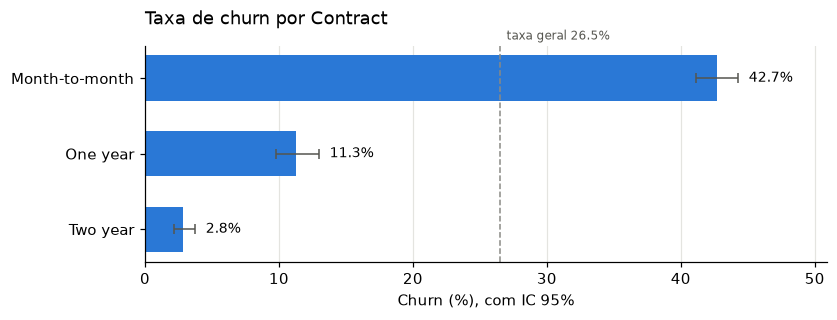

,Clientes,Churn (%),IC 95% inf (%),IC 95% sup (%)
InternetService,,,,
Fiber optic,3096,41.9%,40.2%,43.6%
DSL,2421,19.0%,17.4%,20.6%
No,1526,7.4%,6.2%,8.8%


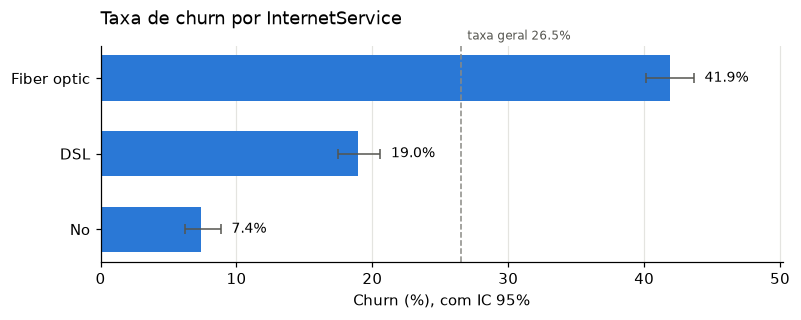

,Clientes,Churn (%),IC 95% inf (%),IC 95% sup (%)
PaymentMethod,,,,
Electronic check,2365,45.3%,43.3%,47.3%
Mailed check,1612,19.1%,17.3%,21.1%
Bank transfer (automatic),1544,16.7%,14.9%,18.7%
Credit card (automatic),1522,15.2%,13.5%,17.1%


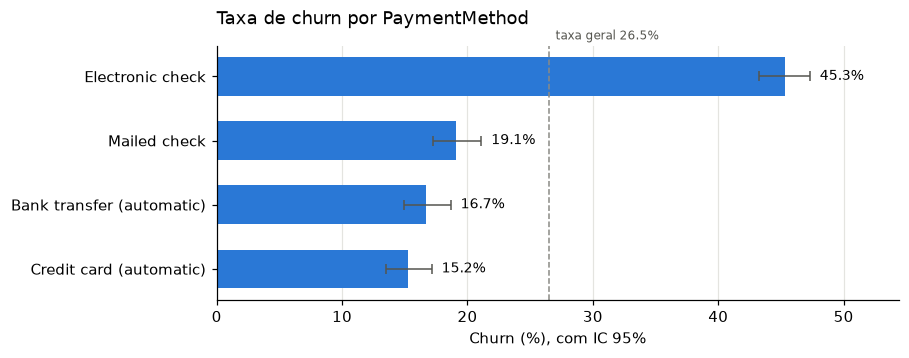

,Clientes,Churn (%),IC 95% inf (%),IC 95% sup (%)
Faixa de tenure (meses),,,,
0 |--- 6,1371,54.3%,51.6%,56.9%
6 |--- 12,698,36.5%,33.0%,40.2%
12 |--- 18,568,33.6%,29.9%,37.6%
18 |--- 24,479,24.6%,21.0%,28.7%
24 |--- 30,453,22.3%,18.7%,26.4%
30 |--- 36,423,21.7%,18.1%,25.9%
36 |--- 42,364,21.7%,17.8%,26.2%
42 |--- 48,384,17.4%,14.0%,21.6%
48 |--- 54,416,15.4%,12.2%,19.2%


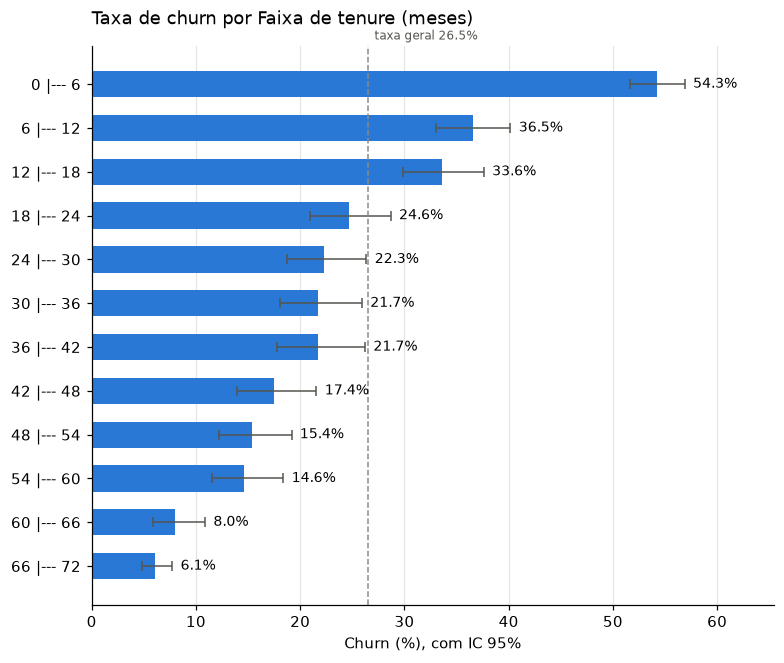

In [7]:
print(f'Taxa geral de churn: {taxa_geral:.1f}%')
df_faixas = df.assign(**{'Faixa de tenure (meses)': classificar(df['tenure'], LARGURA['tenure'])})

for coluna in ['Contract', 'InternetService', 'PaymentMethod', 'Faixa de tenure (meses)']:
    tabela = taxa_churn(df_faixas, coluna)
    if coluna.startswith('Faixa'):
        tabela = tabela.sort_index()  # faixas seguem a ordem natural
    display(tabela.style.format({c: '{:.1f}%' for c in tabela.columns if '%' in c}))

    fig, ax = plt.subplots(figsize=(8, 0.45 * len(tabela) + 1.2))
    erro = [tabela['Churn (%)'] - tabela['IC 95% inf (%)'], tabela['IC 95% sup (%)'] - tabela['Churn (%)']]
    ax.barh(tabela.index.astype(str), tabela['Churn (%)'], color=AZUL, height=0.6,
            xerr=erro, error_kw={'ecolor': TEXTO_SECUNDARIO, 'capsize': 3, 'elinewidth': 1})
    ax.invert_yaxis()
    ax.axvline(taxa_geral, color=CINZA, linestyle='--', linewidth=1)
    ax.annotate(f'taxa geral {taxa_geral:.1f}%', xy=(taxa_geral, 1), xycoords=('data', 'axes fraction'),
                xytext=(4, 2), textcoords='offset points', fontsize=8, color=TEXTO_SECUNDARIO, va='bottom')
    for i, (v, sup) in enumerate(zip(tabela['Churn (%)'], tabela['IC 95% sup (%)'])):
        ax.text(sup + 0.8, i, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_xlim(0, tabela['IC 95% sup (%)'].max() * 1.15)
    ax.set_xlabel('Churn (%), com IC 95%')
    ax.set_title(f'Taxa de churn por {coluna}', loc='left', pad=14)
    ax.grid(axis='y', visible=False)
    if coluna == 'Contract':
        fig.savefig(f'{FIGURAS}/churn_por_contrato.png', dpi=150, bbox_inches='tight')
    plt.show()

## 5. Análise de sobrevivência

`tenure` é o tempo até o cliente sair. Para quem ainda não saiu, é só o tempo observado até agora: um dado **censurado**, porque o cliente pode sair depois. A curva de **Kaplan-Meier** estima, para cada mês, a proporção de clientes que continuam na base, aproveitando também esses dados censurados.

O teste **log-rank** compara as curvas entre grupos.

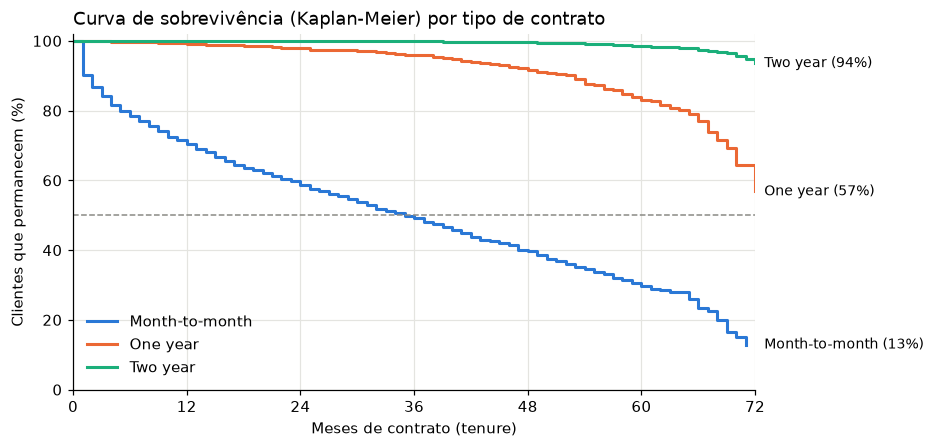

,Clientes,Mediana (meses),Permanece 12 meses,Permanece 24 meses,Permanece 72 meses
Month-to-month,"3,875",35,70.3%,58.6%,12.9%
One year,"1,473",não atinge 50%,99.1%,97.8%,56.8%
Two year,"1,695",não atinge 50%,100.0%,100.0%,93.6%


In [8]:
tempo, evento = df['tenure'], df['Churn'] == 'Yes'
cores = {'Month-to-month': AZUL, 'One year': LARANJA, 'Two year': VERDE}

fig, ax = plt.subplots(figsize=(8, 4.2))
resumo_sobrevivencia = {}
for contrato, cor in cores.items():
    m = df['Contract'] == contrato
    curva = kaplan_meier(tempo[m], evento[m])
    s = curva['Sobrevivência']
    ax.step(s.index, s.values * 100, where='post', color=cor, linewidth=2, label=contrato)
    ax.annotate(f'{contrato} ({s.iloc[-1]:.0%})', (72, s.iloc[-1] * 100), xytext=(6, 0),
                textcoords='offset points', va='center', fontsize=9)
    resumo_sobrevivencia[contrato] = {
        'Clientes': int(m.sum()),
        'Mediana (meses)': mediana_sobrevivencia(curva),
        'Permanece 12 meses': s.asof(12),
        'Permanece 24 meses': s.asof(24),
        'Permanece 72 meses': s.asof(72),
    }
ax.axhline(50, color=CINZA, linestyle='--', linewidth=1)
ax.set_xlim(0, 72)
ax.set_ylim(0, 102)
ax.set_xticks(range(0, 73, 12))
ax.set_xlabel('Meses de contrato (tenure)')
ax.set_ylabel('Clientes que permanecem (%)')
ax.set_title('Curva de sobrevivência (Kaplan-Meier) por tipo de contrato', loc='left')
ax.legend(loc='lower left', frameon=False)
fig.savefig(f'{FIGURAS}/sobrevivencia_por_contrato.png', dpi=150, bbox_inches='tight')
plt.show()

fmt_pct = {c: '{:.1%}' for c in ['Permanece 12 meses', 'Permanece 24 meses', 'Permanece 72 meses']}
display(pd.DataFrame(resumo_sobrevivencia).T.style.format({**fmt_pct, 'Clientes': '{:,.0f}', 'Mediana (meses)': '{:.0f}'},
                                                            na_rep='não atinge 50%'))

In [9]:
log_rank = pd.DataFrame({c: teste_log_rank(tempo, evento, df[c])
                         for c in ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'gender']}).T
display(log_rank.sort_values('Qui-quadrado', ascending=False)
                .style.format({'Qui-quadrado': '{:,.1f}', 'gl': '{:.0f}', 'p-valor': '{:.2e}'}))

,Qui-quadrado,gl,p-valor
Contract,"2,352.9",2,0.00e+00
TechSupport,989.6,2,1.32e-215
PaymentMethod,865.2,3,3.07e-187
InternetService,520.1,2,1.14e-113
gender,0.5,1,4.68e-01


## 6. Testes de associação com o churn

- **Categóricas:** qui-quadrado de independência. O tamanho do efeito é medido pelo **V de Cramér** (cerca de 0,1 é pequeno, 0,3 é médio e 0,5 é grande).
- **Contínuas:** Mann-Whitney comparando quem saiu e quem ficou, porque as distribuições não são normais. O efeito é medido pela **correlação rank-biserial**, que vai de -1 a 1 e é positiva quando quem saiu tem valores maiores.

Com 7 mil clientes, quase qualquer diferença dá p-valor < 0,05. Por isso as tabelas estão ordenadas pelo tamanho do efeito, que é o que mostra a força da associação.

In [10]:
categoricas_X = [c for c in categoricas if c != 'Churn']

qui2 = pd.DataFrame({c: teste_qui_quadrado(df, c) for c in categoricas_X}).T
qui2 = qui2.sort_values('V de Cramér', ascending=False)
display(qui2.style.format({'Qui-quadrado': '{:,.1f}', 'gl': '{:.0f}', 'p-valor': '{:.2e}',
                           'V de Cramér': '{:.3f}'}))

mw = pd.DataFrame({c: teste_mann_whitney(df, c) for c in continuas}).T
mw = mw.sort_values('Rank-biserial', key=abs, ascending=False)
display(mw.style.format({'Mediana (saiu)': '{:,.2f}', 'Mediana (ficou)': '{:,.2f}',
                         'U': '{:,.0f}', 'p-valor': '{:.2e}', 'Rank-biserial': '{:+.3f}'}))

,Qui-quadrado,gl,p-valor,V de Cramér
Contract,"1,184.6",2,5.86e-258,0.410
OnlineSecurity,850.0,2,2.66e-185,0.347
TechSupport,828.2,2,1.44e-180,0.343
InternetService,732.3,2,9.57e-160,0.322
PaymentMethod,648.1,3,3.68e-140,0.303
OnlineBackup,601.8,2,2.08e-131,0.292
DeviceProtection,558.4,2,5.51e-122,0.282
StreamingMovies,375.7,2,2.67e-82,0.231
StreamingTV,374.2,2,5.53e-82,0.231
PaperlessBilling,258.3,1,4.07e-58,0.191


,Mediana (saiu),Mediana (ficou),U,p-valor,Rank-biserial
tenure,10.00,38.00,"2,515,538",2.42e-208,-0.480
TotalCharges,703.55,"1,683.60","3,360,665",2.00e-84,-0.303
MonthlyCharges,79.65,64.43,"6,003,126",3.31e-54,+0.242


## 7. Modelos de previsão

**Colinearidade:** `TotalCharges` é praticamente `tenure × MonthlyCharges`. Com as três variáveis juntas, os coeficientes da regressão logística ficam instáveis e trocam de sinal (por exemplo, `TotalCharges` parecia aumentar o churn). Por isso `TotalCharges` fica de fora dos modelos.

In [11]:
estimado = df['tenure'] * df['MonthlyCharges']
print(f"Correlação entre TotalCharges e tenure × MonthlyCharges: {df['TotalCharges'].corr(estimado):.3f}")

Correlação entre TotalCharges e tenure × MonthlyCharges: 1.000


### 7.1 Variáveis derivadas

- `NumServicos`: quantos dos 8 serviços adicionais o cliente contrata;
- `SemProtecao`: tem internet, mas nem segurança online nem suporte técnico.

A regressão logística é comparada com e sem essas variáveis, por validação cruzada estratificada de 5 partes no conjunto de treino. O conjunto de teste (25%) só é usado no final.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df_modelo = criar_features(df)
y = (df_modelo['Churn'] == 'Yes').astype(int)
treino, teste = train_test_split(df_modelo.index, test_size=0.25, stratify=y, random_state=42)
y_treino, y_teste = y[treino], y[teste]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def pipeline(classificador, numericas, categoricas):
    return make_pipeline(
        ColumnTransformer([
            ('num', StandardScaler(), numericas),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas),
        ]),
        classificador,
    )

conjuntos = {
    'Originais': (['tenure', 'MonthlyCharges'], categoricas_X),
    'Originais + derivadas': (['tenure', 'MonthlyCharges', 'NumServicos'], categoricas_X + ['SemProtecao']),
}
auc_conjuntos = {}
for nome, (num, cat) in conjuntos.items():
    modelo = pipeline(LogisticRegression(max_iter=1000, class_weight='balanced'), num, cat)
    notas = cross_val_score(modelo, df_modelo.loc[treino, num + cat], y_treino, cv=cv, scoring='roc_auc')
    auc_conjuntos[nome] = {'roc_auc (média)': notas.mean(), 'roc_auc (desvio)': notas.std()}
display(pd.DataFrame(auc_conjuntos).T.style.format('{:.4f}'))

escolhido = max(auc_conjuntos, key=lambda k: auc_conjuntos[k]['roc_auc (média)'])
numericas_X, categoricas_modelo = conjuntos[escolhido]
X_treino = df_modelo.loc[treino, numericas_X + categoricas_modelo]
X_teste = df_modelo.loc[teste, numericas_X + categoricas_modelo]
print(f'Conjunto usado daqui em diante: {escolhido}')

,roc_auc (média),roc_auc (desvio)
Originais,0.8425,0.0152
Originais + derivadas,0.8424,0.0148


Conjunto usado daqui em diante: Originais


### 7.2 Comparação de modelos

Três modelos, todos com `class_weight='balanced'`, porque só 26,5% dos clientes saem.

In [13]:
modelos = {
    'Regressão Logística': pipeline(LogisticRegression(max_iter=1000, class_weight='balanced'),
                                    numericas_X, categoricas_modelo),
    'Random Forest': pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                                     random_state=42, n_jobs=-1), numericas_X, categoricas_modelo),
    'Gradient Boosting': pipeline(HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
                                  numericas_X, categoricas_modelo),
}

resultados = {}
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=['roc_auc', 'recall', 'precision', 'f1'])
    resultados[nome] = {f'{m} (média)': r[f'test_{m}'].mean() for m in ['roc_auc', 'recall', 'precision', 'f1']}
    resultados[nome]['roc_auc (desvio)'] = r['test_roc_auc'].std()

comparacao = pd.DataFrame(resultados).T.sort_values('roc_auc (média)', ascending=False)
display(comparacao.style.format('{:.3f}'))
melhor = comparacao.index[0]
print(f'Melhor modelo na validação cruzada: {melhor}')

,roc_auc (média),recall (média),precision (média),f1 (média),roc_auc (desvio)
Regressão Logística,0.842,0.790,0.516,0.624,0.015
Random Forest,0.841,0.757,0.533,0.625,0.015
Gradient Boosting,0.835,0.727,0.538,0.618,0.012


Melhor modelo na validação cruzada: Regressão Logística


### 7.3 Calibração das probabilidades

Com `class_weight='balanced'`, o modelo dá o mesmo peso total às duas classes, como se metade dos clientes saísse. As "probabilidades" ficam infladas: um 0,40 não quer dizer 40% de chance real de cancelar. Na regressão logística, essa distorção é basicamente um deslocamento do intercepto, que a **calibração sigmoide** (Platt, via `CalibratedClassifierCV`) corrige diretamente. A calibração isotônica também foi testada, mas dava riscos de 100% nas pontas da escala, um excesso de confiança.

No gráfico, um modelo bem calibrado fica sobre a diagonal: entre os clientes com risco previsto de 30%, cerca de 30% de fato saem. O **Brier score** mede o erro das probabilidades (quanto menor, melhor).

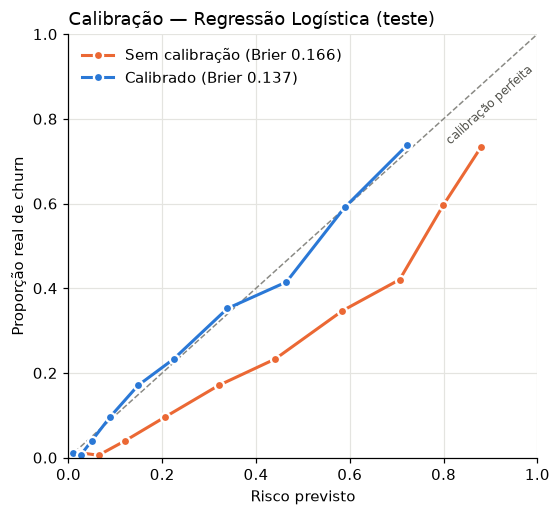

In [14]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import cross_val_predict

sem_calibracao = modelos[melhor].fit(X_treino, y_treino)
calibrado = CalibratedClassifierCV(modelos[melhor], method='sigmoid', cv=5).fit(X_treino, y_treino)
prob = {
    'Sem calibração': sem_calibracao.predict_proba(X_teste)[:, 1],
    'Calibrado': calibrado.predict_proba(X_teste)[:, 1],
}

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=CINZA, linestyle='--', linewidth=1)
ax.annotate('calibração perfeita', (0.80, 0.74), rotation=42, fontsize=8, color=TEXTO_SECUNDARIO)
for (nome, p), cor in zip(prob.items(), (LARANJA, AZUL)):
    real, previsto = calibration_curve(y_teste, p, n_bins=10, strategy='quantile')
    ax.plot(previsto, real, marker='o', markersize=6, color=cor, linewidth=2,
            markeredgecolor='white', markeredgewidth=1.5,
            label=f'{nome} (Brier {brier_score_loss(y_teste, p):.3f})')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('Risco previsto')
ax.set_ylabel('Proporção real de churn')
ax.set_title(f'Calibração — {melhor} (teste)', loc='left')
ax.legend(loc='upper left', frameon=False)
plt.show()

### 7.4 Limiar de decisão pelo custo

Os custos abaixo são **hipotéticos**; ajuste para a realidade do negócio:

- `CUSTO_ACAO`: custo de uma ação de retenção (contato e desconto), aplicada a todo cliente marcado como risco;
- `CUSTO_PERDA`: custo de perder um cliente que cancelaria e não foi abordado.

Com probabilidades calibradas, a teoria diz que vale agir quando `risco × CUSTO_PERDA > CUSTO_ACAO`, ou seja, quando o risco passa de `CUSTO_ACAO / CUSTO_PERDA`. O limiar também é buscado empiricamente, com as probabilidades calibradas da validação cruzada no treino, para conferir.

Limiar teórico: 0.20 | limiar empírico: 0.19


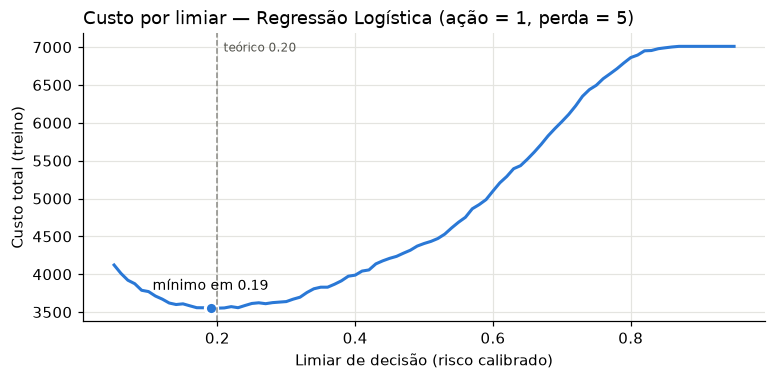

In [15]:
CUSTO_ACAO = 1
CUSTO_PERDA = 5

def custo_total(y_real, prob, limiar):
    tn, fp, fn, tp = confusion_matrix(y_real, prob >= limiar).ravel()
    return (tp + fp) * CUSTO_ACAO + fn * CUSTO_PERDA

prob_cv = cross_val_predict(CalibratedClassifierCV(modelos[melhor], method='sigmoid', cv=5),
                            X_treino, y_treino, cv=cv, method='predict_proba')[:, 1]
limiares = np.round(np.arange(0.05, 0.96, 0.01), 2)
custos = np.array([custo_total(y_treino, prob_cv, l) for l in limiares])
limiar = limiares[custos.argmin()]
limiar_teorico = CUSTO_ACAO / CUSTO_PERDA
print(f'Limiar teórico: {limiar_teorico:.2f} | limiar empírico: {limiar:.2f}')

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(limiares, custos, color=AZUL, linewidth=2)
ax.plot(limiar, custos.min(), 'o', color=AZUL, markersize=8, markeredgecolor='white', markeredgewidth=2)
ax.annotate(f'mínimo em {limiar:.2f}', (limiar, custos.min()), xytext=(0, 12),
            textcoords='offset points', fontsize=9, ha='center')
ax.axvline(limiar_teorico, color=CINZA, linestyle='--', linewidth=1)
ax.annotate(f'teórico {limiar_teorico:.2f}', xy=(limiar_teorico, 1), xycoords=('data', 'axes fraction'),
            xytext=(4, -12), textcoords='offset points', fontsize=8, color=TEXTO_SECUNDARIO)
ax.set_xlabel('Limiar de decisão (risco calibrado)')
ax.set_ylabel('Custo total (treino)')
ax.set_title(f'Custo por limiar — {melhor} (ação = {CUSTO_ACAO}, perda = {CUSTO_PERDA})', loc='left')
plt.show()

### 7.5 Avaliação final no teste

In [16]:
prob_teste = prob['Calibrado']
print(f'Modelo: {melhor} calibrado | ROC-AUC no teste: {roc_auc_score(y_teste, prob_teste):.3f}')
print(f'Acurácia de sempre prever "No": {1 - y_teste.mean():.3f}\n')
for nome_limiar, l in [('0,50', 0.5), (f'por custo {limiar:.2f}', limiar)]:
    print(f'--- Limiar {nome_limiar} | custo no teste: {custo_total(y_teste, prob_teste, l):,}')
    print(classification_report(y_teste, prob_teste >= l, target_names=['Ficou (No)', 'Saiu (Yes)'], digits=3))

Modelo: Regressão Logística calibrado | ROC-AUC no teste: 0.844
Acurácia de sempre prever "No": 0.735

--- Limiar 0,50 | custo no teste: 1,450
              precision    recall  f1-score   support

  Ficou (No)      0.845     0.896     0.870      1294
  Saiu (Yes)      0.654     0.546     0.595       467

    accuracy                          0.803      1761
   macro avg      0.750     0.721     0.732      1761
weighted avg      0.795     0.803     0.797      1761

--- Limiar por custo 0.19 | custo no teste: 1,166
              precision    recall  f1-score   support

  Ficou (No)      0.932     0.648     0.765      1294
  Saiu (Yes)      0.472     0.869     0.611       467

    accuracy                          0.707      1761
   macro avg      0.702     0.759     0.688      1761
weighted avg      0.810     0.707     0.724      1761



### 7.6 Por que cada cliente está em risco

A explicação usa a regressão logística, um modelo linear. Nele, a contribuição de cada variável para a previsão de um cliente é `coeficiente × (valor do cliente − média)`, em log-odds. Esse é exatamente o valor SHAP de um modelo linear, então não é preciso nenhuma biblioteca extra. As colunas one-hot de uma mesma variável são somadas, e a calibração não muda a ordem dos clientes nem os motivos.

Primeiro os coeficientes globais, depois os 10 clientes do teste com maior risco e os 3 fatores que mais pesam para cada um.

`MonthlyCharges` aparece com sinal negativo, apesar de quem sai pagar mais. Isso acontece porque a mensalidade é quase toda explicada pelos serviços contratados (fibra, streaming etc.), que já estão no modelo. O coeficiente mede o efeito de pagar mais **pelos mesmos serviços**, e não o efeito de ter uma mensalidade alta em geral.

In [17]:
logistica = modelos['Regressão Logística'].fit(X_treino, y_treino)
nomes = logistica[0].get_feature_names_out()
coeficientes = pd.Series(logistica[-1].coef_[0], index=nomes).sort_values()
display(pd.concat([coeficientes.head(5), coeficientes.tail(5)])
          .rename('Coeficiente').to_frame()
          .style.format('{:+.3f}'))

,Coeficiente
num__tenure,-0.736
cat__Contract_Two year,-0.726
cat__InternetService_DSL,-0.609
num__MonthlyCharges,-0.540
cat__PaperlessBilling_No,-0.266
cat__OnlineSecurity_No,+0.207
cat__StreamingTV_Yes,+0.264
cat__StreamingMovies_Yes,+0.304
cat__Contract_Month-to-month,+0.647
cat__InternetService_Fiber optic,+0.708


In [18]:
risco = pd.Series(prob_teste, index=X_teste.index, name='Risco calibrado')
top = risco.sort_values(ascending=False).head(10).index
motivos = principais_motivos(contribuicoes(logistica, X_treino, X_teste.loc[top]), X_teste)

ranking = pd.concat([df.loc[top, ['customerID']], risco[top], motivos], axis=1)
display(ranking.style.format({'Risco calibrado': '{:.0%}'}).hide(axis='index'))

customerID,Risco calibrado,Motivo 1,Motivo 2,Motivo 3
5178-LMXOP,86%,tenure = 1 (+0.94),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
6861-XWTWQ,83%,tenure = 7 (+0.76),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
0295-PPHDO,83%,tenure = 1 (+0.94),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
8884-ADFVN,83%,tenure = 7 (+0.76),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
1400-MMYXY,83%,tenure = 3 (+0.88),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
1069-XAIEM,82%,tenure = 1 (+0.94),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
6023-YEBUP,82%,tenure = 3 (+0.88),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
2545-EBUPK,82%,tenure = 2 (+0.91),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
9057-SIHCH,82%,tenure = 3 (+0.88),InternetService = Fiber optic (+0.66),Contract = Month-to-month (+0.48)
2012-NWRPA,81%,InternetService = Fiber optic (+0.66),tenure = 11 (+0.64),Contract = Month-to-month (+0.48)
